# **Description**

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

# **Data Cleaning**

## **Datasets Paths**

In [4]:
business_path ='/content/drive/MyDrive/personal_project/dataset_business.json'
review_path = '/content/drive/MyDrive/personal_project/dataset_review.json'


## **Business Dataset**

In [5]:
# load business dataset in a df
bus_df = pd.read_json(business_path, lines=True)

In [6]:
bus_df.shape

(150346, 14)

In [7]:
# create medical category set using categories column
counts = (
    bus_df['categories'].dropna()
    .str.split(', ').explode()
    .str.strip()
    .value_counts()
)

seed = (r'health|medical|doctor|hospital|clinic|dental|dentist|physic|'
        r'therap|surg|nurse|pharm|diagnos|rehab|psych|counsel|chiro|'
        r'optom|derma|pediatr|orthop|urgent|acupunct|midwif|obstetric|'
        r'cardio|oncol|neuro|radiol|podiatr|allerg|immun|nutrition|'
        r'hospice|home health|assisted living|blood|imaging|laborator')

candidates = counts[counts.index.str.contains(seed, case=False)]
print(candidates.to_string())

categories
Health & Medical                   11890
Doctors                             3763
Dentists                            2528
General Dentistry                   1993
Cosmetic Dentists                   1630
Massage Therapy                     1357
Medical Centers                     1131
Optometrists                        1112
Nurseries & Gardening                892
Medical Spas                         781
Oral Surgeons                        752
Chiropractors                        726
Health Markets                       601
Physical Therapy                     561
Urgent Care                          541
Pediatric Dentists                   528
Pharmacy                             503
Diagnostic Services                  467
Nutritionists                        439
Acupuncture                          424
Hospitals                            395
Cosmetic Surgeons                    367
Dermatologists                       336
Obstetricians & Gynecologists        311
Labor

In [8]:
# manually remove the incorrect category
drop = {'Dentists','General Dentistry','Cosmetic Dentists','Massage Therapy',
        'Optometrists','Nurseries & Gardening','Medical Spas','Oral Surgeons',
        'Chiropractors','Health Markets','Pediatric Dentists','Pharmacy','Acupuncture','Home Health Care','Plastic Surgeons','Emergency Pet Hospital','Psychics','Assisted Living Facilities','Blood & Plasma Donation Centers','Dental Hygienists','Hypnosis/Hypnotherapy','Hospice',
        'Nutritionists','Cosmetic Surgeons','Pediatricians','Rehabilitation Center','Medical Supplies','Laser Eye Surgery/Lasik','Cardio Classes','Cannabis Clinics','Osteopathic Physicians',
        'Cryotherapy','Pet Hospice','Career Counseling','Health Coach','Psychologists','Psychic Mediums','Medical Transportation','Medical Cannabis Referrals','Health Retreats','Medical Law','Halotherapy','Health Insurance Offices','Hydrotherapy','Animal Physical Therapy','Sex Therapists','College Counseling','Sports Psychologists','Animal Assisted Therapy','Storefront Clinics','Sperm Clinic','Dialysis Clinics','Hospitalists'
        }
medical_cats =set(candidates.index) - drop

print(len(medical_cats), 'medical categories kept')
print(medical_cats)

31 medical categories kept
{'Nurse Practitioner', 'Neuropathologists', 'Oncologist', 'Walk-in Clinics', 'Neurotologists', 'Health & Medical', 'Hospitals', 'Dermatologists', 'Speech Therapists', 'Physical Therapy', 'Reproductive Health Services', 'Doctors', 'Occupational Therapy', 'Surgeons', 'Counseling & Mental Health', 'Laboratory Testing', 'Neurologist', 'Medical Centers', 'Podiatrists', 'Ultrasound Imaging Centers', 'Allergists', 'Spine Surgeons', 'Immunodermatologists', 'Psychiatrists', 'Radiologists', 'Diagnostic Imaging', 'Cardiologists', 'Urgent Care', 'Diagnostic Services', 'Obstetricians & Gynecologists', 'Orthopedists'}


In [9]:
# use the created category list to filter bus_df
def is_medical(c):
  if pd.isna(c):
    return False
  return bool(medical_cats & {x.strip() for x in c.split(', ')})

med_bus = bus_df[bus_df['categories'].apply(is_medical)].copy()
med_ids = set(med_bus['business_id'])

In [10]:
med_bus.shape

(11890, 14)

## **Review Dataset**

In [11]:
# load and keep only matching rows in review dataset using med_ids from business dataset
import json

KEEP = ['review_id', 'business_id','user_id','stars','date','text','useful']

rows = []
with open(review_path) as f:
  for line in f:
    r = json.loads(line)
    if r['business_id'] in med_ids:
      rows.append({k: r[k] for k in KEEP})

med_rev = pd.DataFrame(rows)
print(len(med_rev), 'medical reviews')

196580 medical reviews


## **Write Both Datasets to Parquet**

In [12]:
# write both to parquet
out = '/content/drive/MyDrive/personal_project'
med_bus.to_parquet(out + 'medical_businesses.parquet', index=False)
med_rev.to_parquet(out + 'medical_reviews.parquet', index=False)

# **Additional Cleaning**

In [13]:
# reload data
med_bus = pd.read_parquet(out + 'medical_businesses.parquet')
med_rev = pd.read_parquet(out + 'medical_reviews.parquet')

In [14]:
print(med_bus.shape)
print(med_rev.shape)

(11890, 14)
(196580, 7)


### Filter to Only Needed Columns

In [15]:
# create a new sub bus df including only needed columns
sub_med_bus = med_bus[['business_id', 'name','state','stars','review_count','is_open','categories']]

In [16]:
filter1_med_bus = sub_med_bus[(sub_med_bus['categories']=='Hospitals, Health & Medical') | (sub_med_bus['categories'].str.contains('Doctors',na=False))]

In [17]:
print(sub_med_bus.shape)
print(filter1_med_bus.shape)

(11890, 7)
(3814, 7)


### Filter Out More Data in 'Categories' column

In [18]:
exclude = 'Dentists|General Dentistry|Cosmetic Dentists|Massage Therapy|Optometrists|Nurseries & Gardening|Medical Spas|Oral Surgeons|Chiropractors|Health Markets|Pediatric Dentists|Pharmacy|Acupuncture|Home Health Care|Plastic Surgeons|Emergency Pet Hospital|Psychics|Assisted Living Facilities|Blood & Plasma Donation Centers|Dental Hygienists|Hypnosis/Hypnotherapy|Hospice|Nutritionists|Cosmetic Surgeons|Pediatricians|Rehabilitation Center|Medical Supplies|Laser Eye Surgery/Lasik|Cardio Classes|Cannabis Clinics|Osteopathic Physicians|Cryotherapy|Pet Hospice|Career Counseling|Health Coach|Psychologists|Psychic Mediums|Medical Transportation|Medical Cannabis Referrals|Health Retreats|Medical Law|Halotherapy|Health Insurance Offices|Hydrotherapy|Animal Physical Therapy|Sex Therapists|College Counseling|Sports Psychologists|Animal Assisted Therapy|Storefront Clinics|Sperm Clinic|Dialysis Clinics|Hospitalists|Educational Services|Hair Removal|Beauty & Spas|Drugstores|Shopping|Weight Loss|Piercing|Vape Shops|Tattoo|Food|Olive Oil|Specialty Food'

filter2_med_bus = filter1_med_bus[~filter1_med_bus['categories'].str.contains(exclude, case=False, na=False)]
filter2_med_bus.shape

(1904, 7)

### Join Business with Review Data
The goal is to get combined data and use it to run on sentimental analysis on review.

In [19]:
print(filter2_med_bus.shape)
filter2_med_bus.head(3)

(1904, 7)


,business_id,name,state,stars,review_count,is_open,categories
7,P8brGDYVWjeW9GrKixH0yQ,Laser Spine Institute,FL,3.0,36,0,"Medical Centers, Doctors, Diagnostic Services,..."
9,M_THnNDHs29aylcK-JqS1A,Professional Healthcare of Pinellas,FL,1.5,6,1,"Doctors, Internal Medicine, Health & Medical"
17,mq5Z9X7yxgyApILQ11niNw,Wendy Warner- Medicine In Balance,PA,3.0,7,1,"Health & Medical, Doctors, Medical Centers, Lo..."


In [20]:
merged = med_rev.merge(
    filter2_med_bus[['business_id', 'name', 'state', 'stars', 'review_count', 'is_open',
       'categories']],
    on='business_id',
    how='left',
    suffixes=('_review', '_business')
)

print(merged.shape)

(196580, 13)


In [21]:
med_rev.columns

Index(['review_id', 'business_id', 'user_id', 'stars', 'date', 'text',
       'useful'],
      dtype='object')

In [22]:
# drop rows where categories is nan
merged['categories'].isna().value_counts()

,count
categories,
True,166826
False,29754


In [23]:
merged = merged.dropna(subset=['categories']).copy()
merged.shape

(29754, 13)

### Re-order and rename Columns

In [24]:
med_merged = merged[['business_id',
                     'name','state',
                     'categories','stars_business',
                     'review_count','user_id',
                     'review_id','stars_review','useful','text']]\
                     .rename(columns={
                         'name':'business_name',
                         'text':'review_content'
                     })

In [25]:
print(med_merged.shape)
print(med_merged.columns)
print(med_merged.dtypes)

(29754, 11)
Index(['business_id', 'business_name', 'state', 'categories', 'stars_business',
       'review_count', 'user_id', 'review_id', 'stars_review', 'useful',
       'review_content'],
      dtype='object')
business_id        object
business_name      object
state              object
categories         object
stars_business    float64
review_count      float64
user_id            object
review_id          object
stars_review      float64
useful              int64
review_content     object
dtype: object


In [26]:
med_merged.shape

(29754, 11)

# **EDA**

### Star Review Chart

After performing data cleaning and filtering, I conducted exploratory data analysis (EDA) to explore the high level of the dataset. This will assist me in better understand how to answer the core questions of the project.

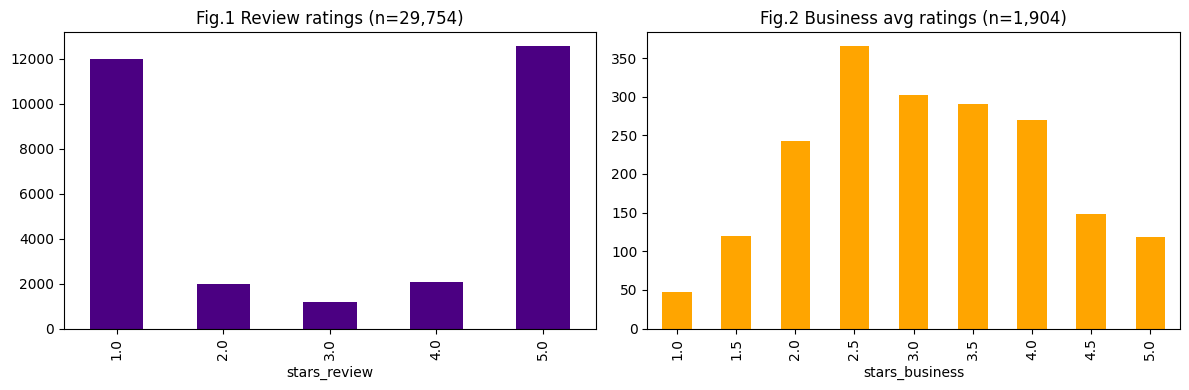

In [27]:
biz = med_merged.drop_duplicates('business_id')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

med_merged['stars_review'].value_counts().sort_index().plot(
    kind='bar', color='indigo', ax=axes[0],
    title=f'Fig.1 Review ratings (n={len(med_merged):,})')

biz['stars_business'].value_counts().sort_index().plot(
    kind='bar', color='orange', ax=axes[1],
    title=f'Fig.2 Business avg ratings (n={len(biz):,})')

plt.tight_layout()

Result in Figure 1 shows the extreme polarized in individual reviews with majority of the reviews in either 1-star or 5-stars, giving a U-shaped distribution. This shows that patients write reviews when an experience is exceptional or infuriating, and rarely when it is merely adequate.

In Figure 2, on the other hand, shows the provider averages across star ratings. We see that provider averages are not polarized with majority clustering in the middle. This bar chart shows the extreme reviews are normalized in business level. Additionally, we see that very few providers are consistently loved (6.2% at 5-stars) or consistently hated (2.5% at 1-star).

When visiting a provider, patients don't just see the provider. There is a whole experience from scheduling an appointment with staff online, check-in interaction with staff, and post appointment service. Therefore, although these findings are useful, they don't directly review a particular element of the whole patient-provider experience. A sentimental analysis will provide more insights on this question as we will look into each review content if patients leave any specific component in their experience that cause the review to be high or low.

### Review Counts Per Business

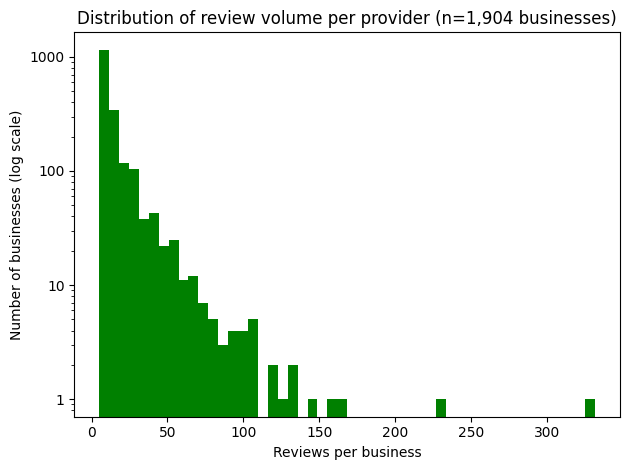

In [28]:
import matplotlib.ticker as mticker

counts = med_merged.groupby('business_id').size()

ax = counts.plot(kind='hist', bins=50, logy=True, color='green',
                 title=f'Distribution of review volume per provider (n={len(counts):,} businesses)')

ax.yaxis.set_major_formatter(mticker.ScalarFormatter())
ax.yaxis.set_minor_formatter(mticker.NullFormatter())

ax.set_xlabel('Reviews per business')
ax.set_ylabel('Number of businesses (log scale)')
plt.tight_layout()
plt.show()

Reviews are spread very unevenly across the 1,904 providers. The typical provider has 9 reviews, but the range runs from 5 to 332, making this a weak evidence on provider's online reputation as a single bag review has more weight on the ones with just handful reviews.

### Review Len vs Rating

/tmp/ipykernel_2748/2104275873.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  means = med_merged.groupby('len_bin')['stars_review'].mean()


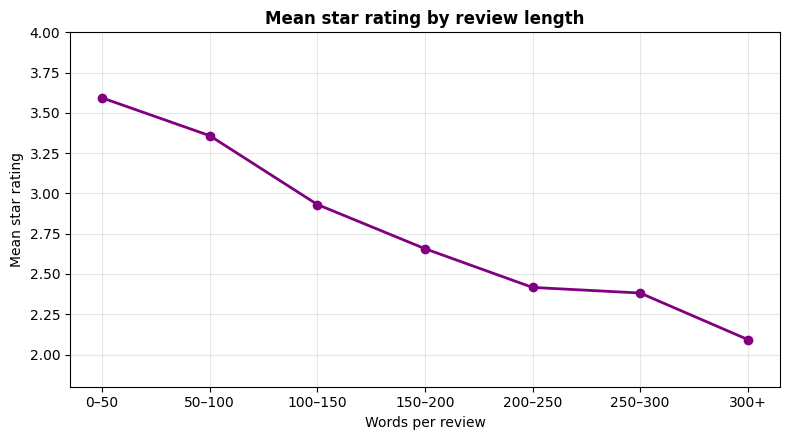

In [29]:
med_merged['w'] = med_merged['review_content'].str.split().str.len()
edges = [0, 50, 100, 150, 200, 250, 300, 10**6]
labs = ['0–50', '50–100', '100–150', '150–200', '200–250', '250–300', '300+']
med_merged['len_bin'] = pd.cut(med_merged['w'], edges, labels=labs)

means = med_merged.groupby('len_bin')['stars_review'].mean()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(means.index, means.values, marker='o', color='purple', linewidth=2)

ax.set_title('Mean star rating by review length', fontweight='bold')
ax.set_xlabel('Words per review')
ax.set_ylabel('Mean star rating')
ax.set_ylim(1.8, 4)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Line chart above shows the mean star rating declines as review length increases. For instance, reviews of fewer than 100 words average 3.3 stars whereas those exceeding 300 words average 2.1 stars. We also notice taht the decline is modest below 100 words but steepens through the 100-150 and 300+ bins, suggesting longer reviews are predominantly critical. This is an interesting finding because despite being a purely structural feature requiring no analysis of content. It displays how patients document care experience: complaints require explaining what happened and who was involved, which satisfaction need only a couple sentences. This will be useful in sentimental analsyis as we want to identify root cause of satisfaction and improve from there.

# Methods and Experiments

The exploratory analysis showed that patient ratings are strongly polarised, with the large majority falling at either one or five stars, and that this polarisation persists within individual providers. This means the rating alone carries little explanatory content as it indicates that experiences differ sharply but not why. Therefore, analysis of the review text is consequently required to identify the underlying drivers of patient satisfaction and to support actionable recommendations for healthcare providers.

Recurring themes were identified through topic modelling. Reviews were first converted to a TF-IDF (term frequency–inverse document frequency) vector representation, in which each term receives a weight that rises with its frequency within a review and falls with the number of reviews containing it, so that ubiquitous terms are suppressed and distinctive ones emphasised. After that, non-negative matrix factorisation (NMF) was applied to identify eight topics. Each topic consists of a set of terms that tend to appear together across reviews, and each review is assigned to the topic it matches most closely.

In [30]:
# convert text to numbers
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_df=0.5, min_df=25,
                        stop_words='english', ngram_range=(1, 2))

X = tfidf.fit_transform(med_merged['review_content'].fillna(''))
vocab = tfidf.get_feature_names_out()

print(X.shape)

(29754, 9337)


In [31]:
# find the topics
# each topic is a list of words that are grouped together. They are grouped together based on co-occur in the reviews
from sklearn.decomposition import NMF

nmf = NMF(n_components=8, random_state=0, max_iter=400)
W = nmf.fit_transform(X)

med_merged['topic'] = W.argmax(axis=1)

In [32]:
# read the topics
# print out all topics and words in each topic
# review each list and give it a theme name in a NAME list
for k in range(8):
    terms = vocab[nmf.components_[k].argsort()[-10:][::-1]]
    sub = med_merged[med_merged['topic'] == k]
    print(f"Topic {k}: {', '.join(terms)}")
    print(f"  {len(sub):,} reviews | mean {sub['stars_review'].mean():.2f} stars\n")

Topic 0: told, said, insurance, doctor, just, called, did, didn, asked, went
  4,788 reviews | mean 1.57 stars

Topic 1: dr, years, best, feel, time, ve, practice, patient, like, questions
  5,426 reviews | mean 4.08 stars

Topic 2: care, urgent, urgent care, facility, primary, primary care, medical, best urgent, best, seen
  2,495 reviews | mean 3.57 stars

Topic 3: appointment, minutes, waiting, wait, time, room, hour, waiting room, waited, 30
  4,220 reviews | mean 2.23 stars

Topic 4: office, staff, office staff, doctors, appointment, doctor, rude, practice, phone, medical
  3,316 reviews | mean 2.24 stars

Topic 5: hospital, er, nurses, room, doctors, nurse, emergency, hours, care, people
  3,649 reviews | mean 2.80 stars

Topic 6: great, staff, friendly, recommend, highly, highly recommend, professional, helpful, experience, nice
  3,798 reviews | mean 4.67 stars

Topic 7: surgery, pain, surgeon, knee, therapy, physical, center, physical therapy, parathyroid, did
  2,062 reviews 

We used NMF to find the topics. Each topic is a list of words that are grouped together based on their co-occurances. After running NMF, we got 8 topics as shown in Figure X. Each list contains a group words that are found to co-occur together in the reviews. For instance, in Topic 3, we have terms such as 'appointment', 'waiting', 'time', showing their theme of appointment and delay time. After obtaining these Topics, each topic was given a theme name. For example, Topic 3 theme name would be 'Waiting and appointment delays'. These theme name will assist us to group review and average stars in each topic, allowing better understanding and drawing meaningful interpretation from the results. The result can be seen in Figure Y.

In [33]:
# summarize
# after giving name to each list, we run to find total reviews and mean stars of each list
# this shows reasons of why high or low stars reviews
NAMES = {0: 'Disputed interactions', 1: 'Continuity of care', 2: 'Urgent and primary care settings',
         3: 'Waiting and appointment delays', 4: 'Administrative staff interactions', 5: 'Hospitals and emergency care',
         6: 'Positive staff experience', 7: 'Surgical and rehabilitation care'}

med_merged['topic_name'] = med_merged['topic'].map(NAMES)

(med_merged.groupby('topic_name')['stars_review']
 .agg(reviews='size', mean_stars='mean')
 .assign(pct=lambda d: (d.reviews / len(med_merged) * 100).round(1))
 .sort_values('mean_stars', ascending=False).round(2))

,reviews,mean_stars,pct
topic_name,,,
Positive staff experience,3798,4.67,12.8
Continuity of care,5426,4.08,18.2
Urgent and primary care settings,2495,3.57,8.4
Surgical and rehabilitation care,2062,3.43,6.9
Hospitals and emergency care,3649,2.80,12.3
Administrative staff interactions,3316,2.24,11.1
Waiting and appointment delays,4220,2.23,14.2
Disputed interactions,4788,1.57,16.1


In [34]:
!pip install -q vaderSentiment
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()
med_merged['sentiment'] = med_merged['review_content'].fillna('').apply(
    lambda t: sia.polarity_scores(t)['compound'])

med_merged['sentiment'].describe()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 7.9 MB/s eta 0:00:00


,sentiment
count,29754.000000
mean,0.296438
std,0.759145
min,-0.999200
25%,-0.553950
50%,0.740900
75%,0.947800
max,0.999600


In [35]:
# run regression to find association/correlation between star review and topic name and sentitment score
import statsmodels.formula.api as smf

model = smf.ols('stars_review ~ C(topic_name) + sentiment',
                data=med_merged).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           stars_review   R-squared:                       0.579
Model:                            OLS   Adj. R-squared:                  0.579
Method:                 Least Squares   F-statistic:                     5119.
Date:                Sat, 01 Aug 2026   Prob (F-statistic):               0.00
Time:                        21:15:58   Log-Likelihood:                -47683.
No. Observations:               29754   AIC:                         9.538e+04
Df Residuals:                   29745   BIC:                         9.546e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                                                        coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------

In [36]:
med_merged.head(3)

,business_id,business_name,state,categories,stars_business,review_count,user_id,review_id,stars_review,useful,review_content,w,len_bin,topic,topic_name,sentiment
3,fjAbzsW03bW3EvC4-e184g,Penn Dermatology,PA,"Dermatologists, Doctors, Health & Medical",2.0,13.0,XLd5uU0OLOnogy_kefXslw,4VBh_hoFiDly0vJffgV_JQ,5.0,1,I was a little worried about seeing the review...,36,0–50,4,Administrative staff interactions,0.8844
4,q0Fi4n7shUTmlxl-mMPVXA,Banner Urgent Care,AZ,"Doctors, Urgent Care, Health & Medical, Emerge...",3.5,13.0,4mbLmbA-thaDIZTlgxsaCQ,er-igpuhBprkQPfct63ktA,2.0,1,My18 year old daughter had a severe soar throa...,156,150–200,2,Urgent and primary care settings,-0.0792
10,RPxrAiJ3krxtv-UQmt0RlQ,Orange Grove Family Practice,AZ,"Doctors, Family Practice, Health & Medical",2.0,36.0,6LYVWmmUMgyZYnvKhobgXg,2epU691r0mnuct0ThnSJKg,4.0,1,"We see Dr. Gloudemans, and she's a wonderful d...",108,100–150,4,Administrative staff interactions,0.4738


<Axes: title={'center': 'Distribution of VADER sentiment scores'}, ylabel='Frequency'>

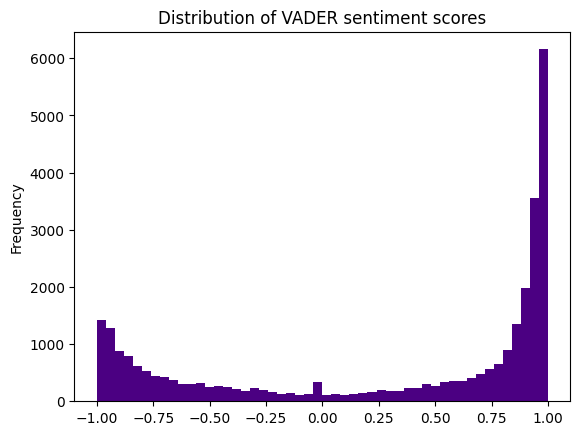

In [42]:
med_merged['sentiment'].plot.hist(bins=50, title = 'Distribution of VADER sentiment scores', color='indigo')

# Interpretations and Recommendations

Based on the analysis, several key insights emerge to explain and attempt to answer the core questions of the project: *What recurring themes and sentiment patterns emerge from patient reviews?* and *Which aspects of patient experience are more strongly associated with overall satisfaction?*


Recurring themes were established along with their sentiment scores as shown in Figure Topics Table. Moreover, sentiment patterns shows a systematic asymmetry. Positive reviews were expressed brieftly and in generalized terms as seen in Line chart of average star ratings by review length, less than 100 words. On the contrary, negative reviews were substainially longer and structured as narrative accounts of specific incidents (i.e. wait time delay).

Sentitment score aligned closely with star ratings at the positive end. Inspection of these cases indicates that they typically combine praise for clinical staff with criticism of administrative processes, suggesting that a single negative aspect can determine the overall rating despite otherwise favourable evaluation.

Additionally, the result from topic modeling shows the association between the patients overall satisfaction with positive staff experience and consistent long-term care.